# Dữ liệu và EDA

EDA thiết kế trên train. Các bảng và hình do pipeline chung tạo; không fit thêm trên test.

Chạy `python -m telco_retention run-all` trước. Notebook sử dụng artifacts và logic của package, không có mô hình thứ hai độc lập.

In [1]:
from telco_retention.common import ROOT, latest_run, read_json
import pandas as pd
from IPython.display import display, Image
run = latest_run()
print('Run:', run.name)

Run: 20261003T133607624165Z-88be4b93


In [2]:
display(read_json(ROOT / 'data/raw/source.json'))
display(read_json(ROOT / 'data/processed/quality.json'))

{'source': 'Kaggle blastchar/telco-customer-churn',
 'url': 'https://www.kaggle.com/api/v1/datasets/download/blastchar/telco-customer-churn',
 'dataset_page': 'https://www.kaggle.com/datasets/blastchar/telco-customer-churn',
 'original_filename': 'WA_Fn-UseC_-Telco-Customer-Churn.csv',
 'downloaded_at_utc': '2026-10-03T11:36:37.024155+00:00',
 'sha256': '88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a',
 'rows': 7043,
 'columns': ['customerID',
  'gender',
  'SeniorCitizen',
  'Partner',
  'Dependents',
  'tenure',
  'PhoneService',
  'MultipleLines',
  'InternetService',
  'OnlineSecurity',
  'OnlineBackup',
  'DeviceProtection',
  'TechSupport',
  'StreamingTV',
  'StreamingMovies',
  'Contract',
  'PaperlessBilling',
  'PaymentMethod',
  'MonthlyCharges',
  'TotalCharges',
  'Churn'],
 'attempts': [],
 'version': 'Snapshot identified by SHA-256; upstream version not supplied by download endpoint',
 'license_note': 'Dataset attribution: IBM sample / BlastChar. Consul

{'rows_before': 7043,
 'rows_after': 7043,
 'duplicates_removed': 0,
 'total_charges_missing_before': 11,
 'total_charges_filled_zero': 11,
 'missing_before': {'customerID': 0,
  'gender': 0,
  'SeniorCitizen': 0,
  'Partner': 0,
  'Dependents': 0,
  'tenure': 0,
  'PhoneService': 0,
  'MultipleLines': 0,
  'InternetService': 0,
  'OnlineSecurity': 0,
  'OnlineBackup': 0,
  'DeviceProtection': 0,
  'TechSupport': 0,
  'StreamingTV': 0,
  'StreamingMovies': 0,
  'Contract': 0,
  'PaperlessBilling': 0,
  'PaymentMethod': 0,
  'MonthlyCharges': 0,
  'TotalCharges': 0,
  'Churn': 0},
 'missing_after': {'customerID': 0,
  'gender': 0,
  'SeniorCitizen': 0,
  'Partner': 0,
  'Dependents': 0,
  'tenure': 0,
  'PhoneService': 0,
  'MultipleLines': 0,
  'InternetService': 0,
  'OnlineSecurity': 0,
  'OnlineBackup': 0,
  'DeviceProtection': 0,
  'TechSupport': 0,
  'StreamingTV': 0,
  'StreamingMovies': 0,
  'Contract': 0,
  'PaperlessBilling': 0,
  'PaymentMethod': 0,
  'MonthlyCharges': 0,
  '

In [3]:
display(pd.read_csv(run / 'eda_segments.csv'))
display(pd.read_csv(run / 'correlations.csv'))

,attribute,group,n,churn_rate,mean_monthly_charges,mean_tenure
0,Contract,Month-to-month,2304,0.430556,66.766927,18.046007
1,Contract,One year,896,0.110491,65.028013,41.955357
2,Contract,Two year,1025,0.029268,60.568976,56.488780
3,tenure_segment,new,1318,0.477238,56.492451,4.809560
4,tenure_segment,developing,615,0.278049,60.427317,18.250407
5,tenure_segment,loyal,2292,0.140052,70.924716,52.141361
6,charges_band,"(18.398999999999997, 35.4]",1059,0.107649,22.153541,28.456091
7,charges_band,"(35.4, 70.55]",1058,0.252363,55.667155,26.155009
8,charges_band,"(70.55, 90.1]",1053,0.365622,80.643447,30.269706
9,charges_band,"(90.1, 118.75]",1055,0.336493,101.332038,44.919431


,feature,tenure,MonthlyCharges,TotalCharges,churn
0,tenure,1.000000,0.253173,0.827843,-0.344764
1,MonthlyCharges,0.253173,1.000000,0.653347,0.197601
2,TotalCharges,0.827843,0.653347,1.000000,-0.191469
3,churn,-0.344764,0.197601,-0.191469,1.000000


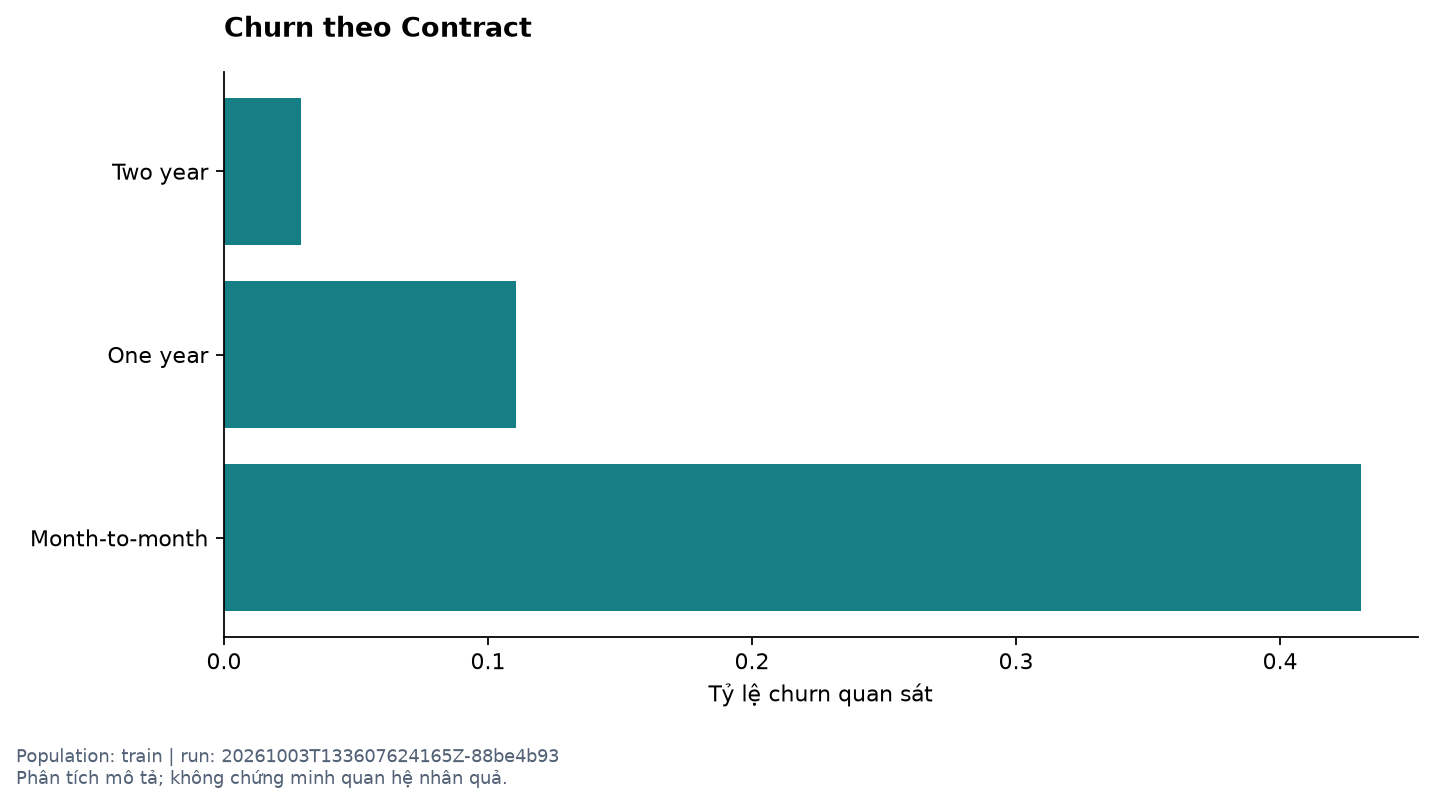

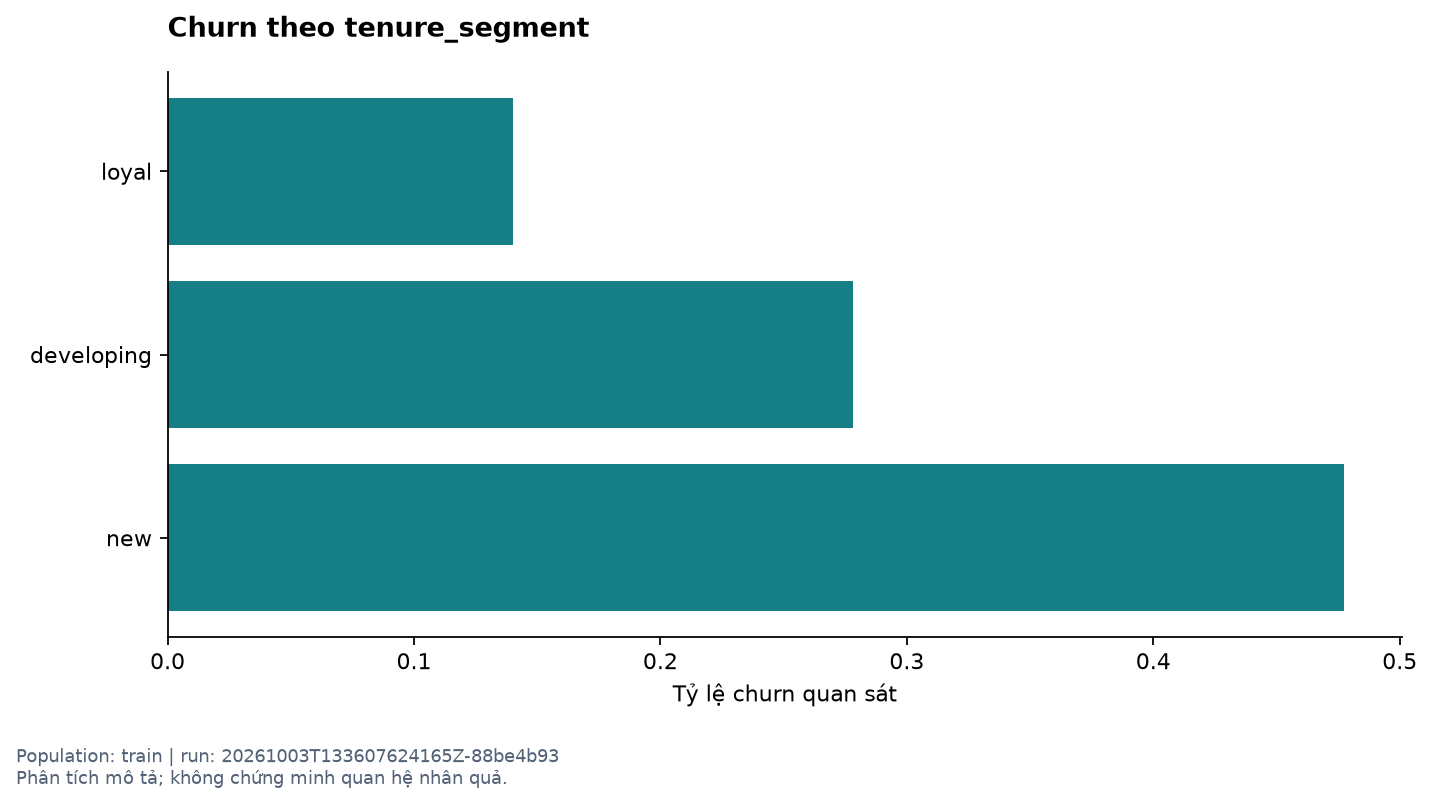

In [4]:
display(Image(filename=str(ROOT / 'reports/figures/eda_contract.png')))
display(Image(filename=str(ROOT / 'reports/figures/eda_tenure.png')))